In [4]:
import warnings
warnings.filterwarnings('ignore')

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import lime.lime_tabular
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

np.random.seed(123)
pd.set_option('display.max_colwidth', None)
print('shap', shap.__version__)

shap 0.54.1


In [5]:
data = pd.read_csv('dataset/winequality-red.csv')
print(data.shape)
print(data.isna().sum().sum(), 'valores em falta')

features = data.drop(columns=['quality'])
labels = data['quality']
feature_names = list(features.columns)

x_train, x_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=123)
print(x_train.shape, x_test.shape)

(1599, 12)
0 valores em falta
(1279, 11) (320, 11)


In [6]:
t0 = time.time()
model = RandomForestRegressor(n_estimators=300, max_depth=30, random_state=123, n_jobs=-1)
model.fit(x_train, y_train)
print(f'R² teste = {model.score(x_test, y_test):.3f}  ({time.time() - t0:.0f}s)')

pred = model.predict(x_test)

R² teste = 0.496  (0s)


In [7]:
explainer = shap.TreeExplainer(model)
t0 = time.time()
sv = explainer(x_test)
print(f'{sv.shape} valores SHAP em {time.time() - t0:.0f}s')
print('Base value (previsão média):', round(float(np.ravel(explainer.expected_value)[0]), 3))

(320, 11) valores SHAP em 5s
Base value (previsão média): 5.631


# 1 · Explicar vinhos individuais

In [8]:
def wine_row(i):
    vals = sv[i].values
    base = float(sv[i].base_values)
    top3 = np.argsort(-np.abs(vals))[:3]
    return {
        'Wine': x_test.index[i],
        'Real': y_test.iloc[i],
        'Predicted quality': round(pred[i], 3),
        'Base value': round(base, 3),
        'Top 3 features (SHAP value)': '; '.join(f'{feature_names[j]} ({vals[j]:+.3f})' for j in top3),
        'Base + Σ SHAP': round(base + vals.sum(), 3),
    }

table_25 = pd.DataFrame([wine_row(i) for i in range(25)])
table_5 = table_25.iloc[:5]
table_20 = table_25.iloc[5:25]

display(table_5)
display(table_20)

,Wine,Real,Predicted quality,Base value,Top 3 features (SHAP value),Base + Σ SHAP
0,912,6,6.560,5.631,alcohol (+0.696); total sulfur dioxide (+0.164); free sulfur dioxide (-0.038),6.560
1,772,5,5.027,5.631,alcohol (-0.326); total sulfur dioxide (-0.119); sulphates (-0.101),5.027
2,1037,5,4.960,5.631,alcohol (-0.288); volatile acidity (-0.285); sulphates (-0.101),4.960
3,1106,6,6.317,5.631,alcohol (+0.613); sulphates (-0.326); volatile acidity (+0.235),6.317
4,263,5,5.640,5.631,alcohol (-0.356); volatile acidity (+0.248); sulphates (+0.115),5.640


,Wine,Real,Predicted quality,Base value,Top 3 features (SHAP value),Base + Σ SHAP
5,1029,7,6.573,5.631,alcohol (+0.249); total sulfur dioxide (+0.152); citric acid (+0.149),6.573
6,935,6,6.193,5.631,alcohol (+0.519); total sulfur dioxide (-0.182); volatile acidity (+0.150),6.193
7,1280,6,5.857,5.631,sulphates (+0.085); alcohol (+0.055); density (+0.033),5.857
8,31,6,5.577,5.631,sulphates (-0.150); alcohol (+0.119); volatile acidity (-0.071),5.577
9,512,6,5.430,5.631,alcohol (-0.348); sulphates (+0.165); volatile acidity (+0.140),5.430
10,61,5,5.017,5.631,alcohol (-0.388); total sulfur dioxide (-0.147); volatile acidity (-0.094),5.017
11,278,8,6.860,5.631,alcohol (+0.699); sulphates (+0.243); volatile acidity (+0.184),6.860
12,233,5,5.320,5.631,sulphates (-0.386); alcohol (+0.115); citric acid (-0.028),5.320
13,569,6,6.017,5.631,alcohol (+0.457); sulphates (-0.223); volatile acidity (+0.206),6.017
14,798,6,5.693,5.631,sulphates (-0.278); alcohol (+0.178); total sulfur dioxide (+0.056),5.693


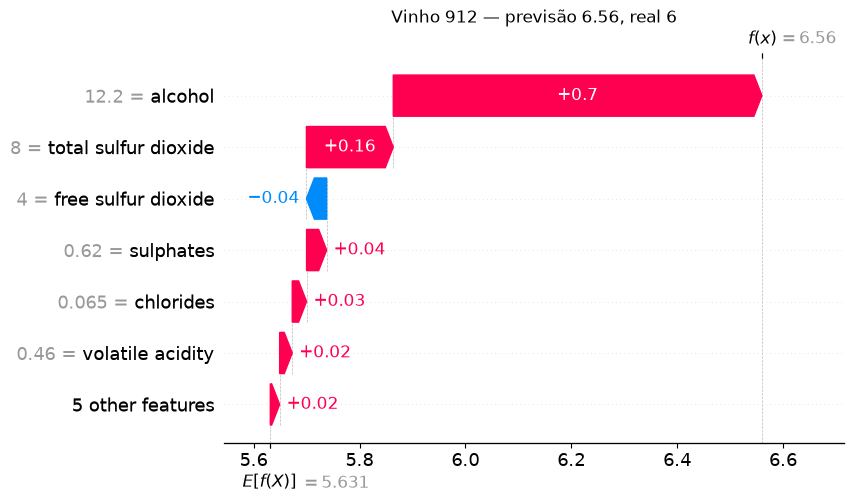

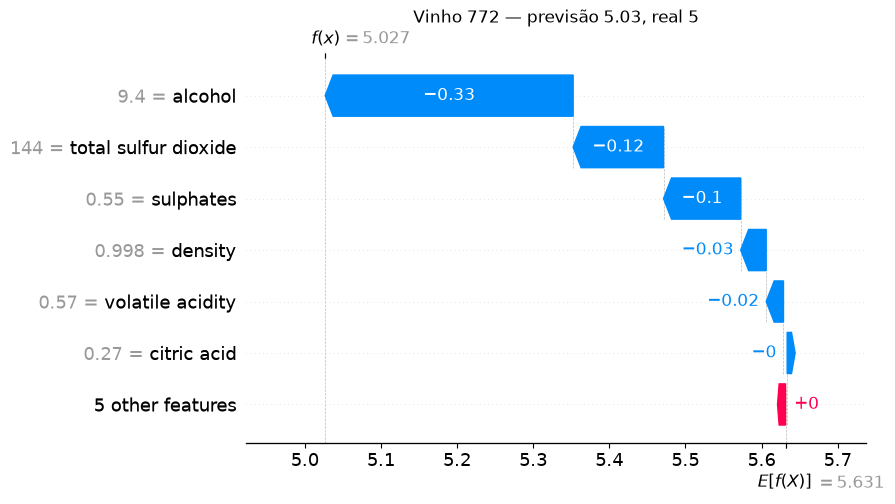

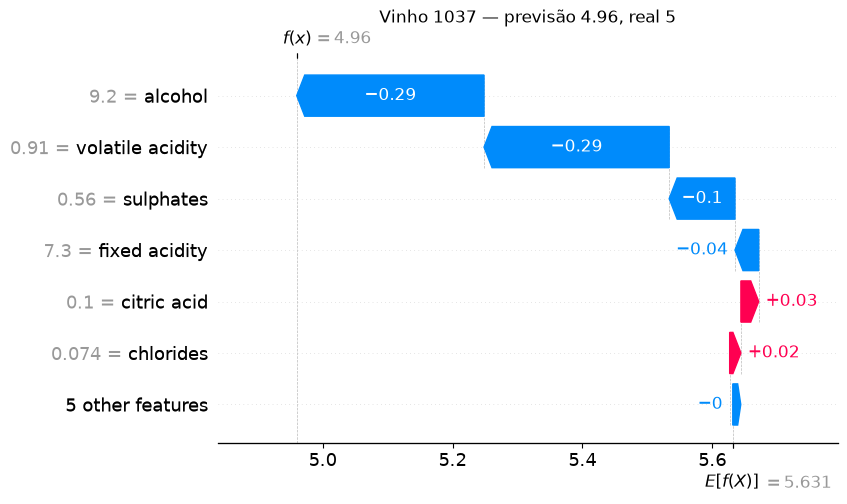

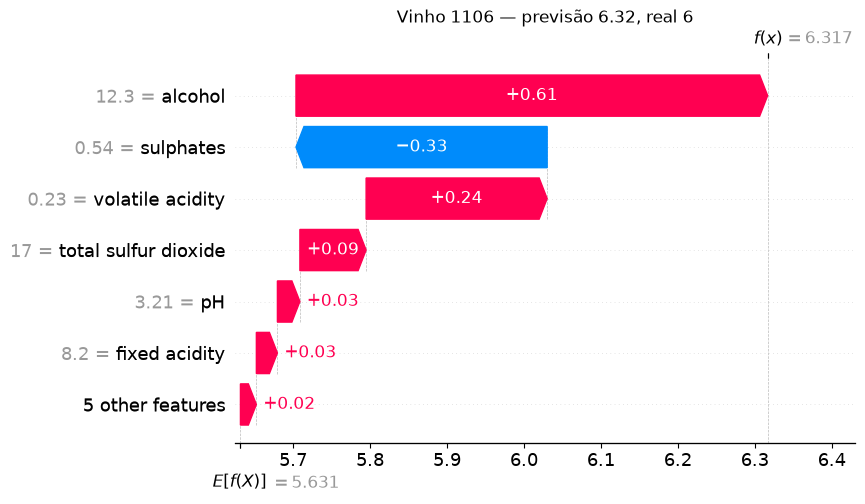

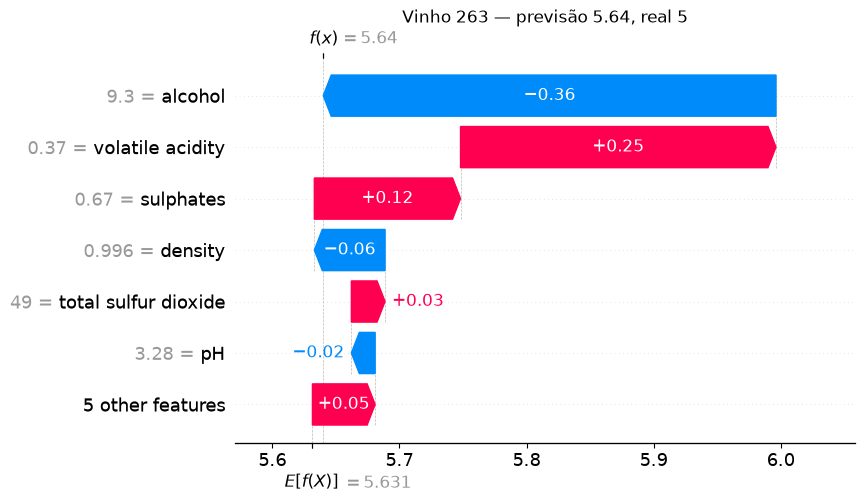

In [9]:
for i in range(5):
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=7, show=False)
    plt.title(f'Vinho {x_test.index[i]} — previsão {pred[i]:.2f}, real {y_test.iloc[i]}')
    plt.savefig(f'p1_waterfall_{i}.png', dpi=150, bbox_inches='tight')
    plt.show()

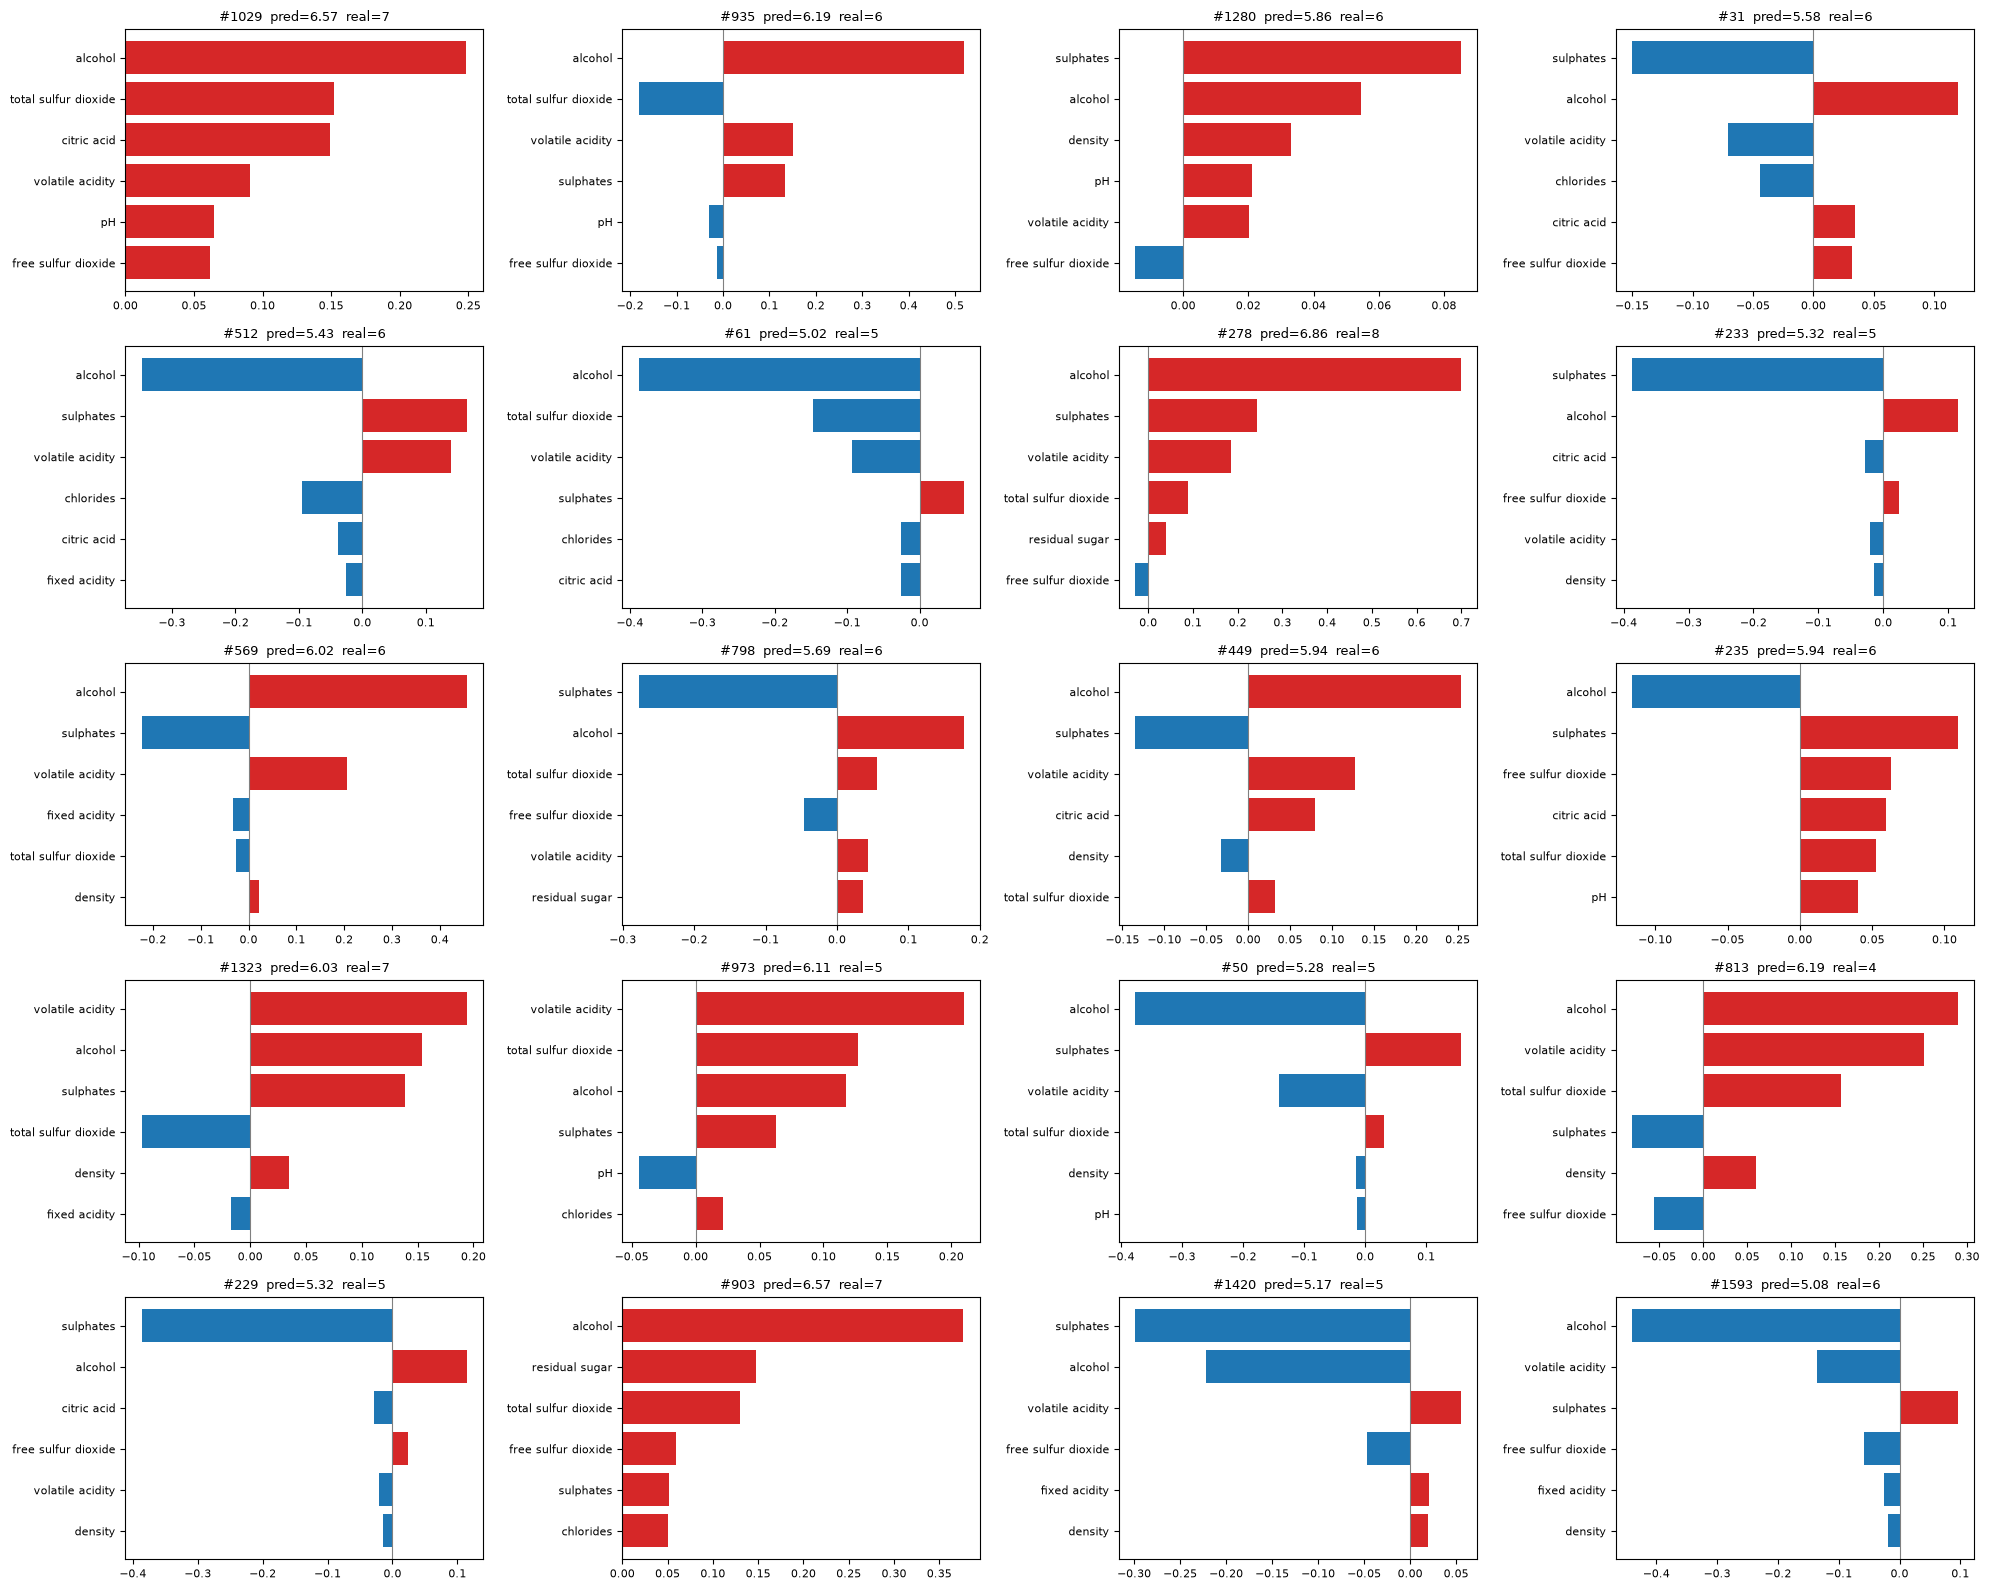

In [10]:
def plot_grid_shap(idx, ncols=4, top=6, fname='p1_grid_20.png'):
    idx = list(idx)
    nrows = int(np.ceil(len(idx) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.2 * nrows))
    for ax, i in zip(axes.flat, idx):
        vals = sv[i].values
        order = np.argsort(np.abs(vals))[-top:]
        ax.barh([feature_names[j] for j in order], vals[order],
                color=['tab:red' if vals[j] > 0 else 'tab:blue' for j in order])
        ax.axvline(0, color='grey', lw=0.8)
        ax.set_title(f'#{x_test.index[i]}  pred={pred[i]:.2f}  real={y_test.iloc[i]}', fontsize=9)
        ax.tick_params(labelsize=8)
    for ax in axes.flat[len(idx):]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

plot_grid_shap(range(5, 25))

In [11]:
sv_20 = pd.DataFrame(sv.values[5:25], columns=feature_names, index=table_20['Wine'])
summary_20 = pd.DataFrame({
    'Sobe (+)': (sv_20 > 0).sum(),
    'Desce (-)': (sv_20 < 0).sum(),
    'SHAP médio': sv_20.mean().round(3),
    'Mean |SHAP|': sv_20.abs().mean().round(3),
}).sort_values('Mean |SHAP|', ascending=False)
display(summary_20)

,Sobe (+),Desce (-),SHAP médio,Mean |SHAP|
alcohol,14,6,0.090,0.279
sulphates,11,9,-0.032,0.163
volatile acidity,13,7,0.060,0.110
total sulfur dioxide,16,4,0.022,0.067
free sulfur dioxide,10,10,0.001,0.030
citric acid,9,11,0.013,0.028
chlorides,13,7,0.002,0.024
density,10,10,0.007,0.022
residual sugar,12,8,0.014,0.020
pH,8,12,0.000,0.019


In [12]:
recon = sv.base_values + sv.values.sum(axis=1)
print('Maior diferença |base + ΣSHAP − previsão| no teste:', np.abs(recon - pred).max())

Maior diferença |base + ΣSHAP − previsão| no teste: 1.7763568394002505e-14


alcohol sobe a previsão em 168 vinhos e baixa em 152


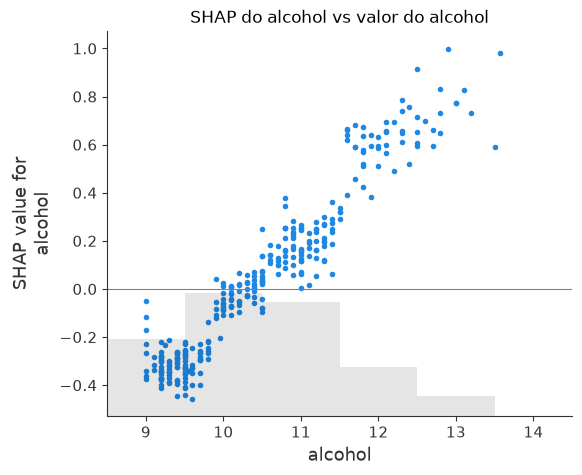

In [13]:
alc = sv[:, 'alcohol']
print('alcohol sobe a previsão em', (alc.values > 0).sum(), 'vinhos e baixa em', (alc.values < 0).sum())

shap.plots.scatter(alc, show=False)
plt.axhline(0, color='grey', lw=0.8)
plt.title('SHAP do alcohol vs valor do alcohol')
plt.savefig('p1_alcohol.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
i_best, i_worst = pred.argmax(), pred.argmin()
diff = pd.DataFrame({
    'Valor (melhor)': x_test.iloc[i_best].values,
    'Valor (pior)': x_test.iloc[i_worst].values,
    'SHAP (melhor)': sv.values[i_best],
    'SHAP (pior)': sv.values[i_worst],
}, index=feature_names)
diff['Diferença SHAP'] = diff['SHAP (melhor)'] - diff['SHAP (pior)']
display(diff.round(3).sort_values('Diferença SHAP', key=abs, ascending=False))

print(f'Melhor: vinho {x_test.index[i_best]}, pred {pred[i_best]:.2f} | Pior: vinho {x_test.index[i_worst]}, pred {pred[i_worst]:.2f}')
print('Diferença das previsões:', round(pred[i_best] - pred[i_worst], 3))
print('Soma das diferenças SHAP:', round(diff['Diferença SHAP'].sum(), 3))

,Valor (melhor),Valor (pior),SHAP (melhor),SHAP (pior),Diferença SHAP
alcohol,12.500,10.000,0.912,-0.058,0.970
sulphates,0.700,0.460,0.287,-0.488,0.775
volatile acidity,0.430,1.000,0.033,-0.557,0.590
total sulfur dioxide,16.000,16.000,0.174,0.002,0.171
fixed acidity,8.900,7.200,0.037,-0.034,0.071
pH,3.350,3.430,0.024,-0.034,0.058
residual sugar,1.900,3.000,0.047,-0.006,0.053
density,0.995,0.996,0.034,0.020,0.013
free sulfur dioxide,6.000,7.000,0.006,-0.007,0.012
citric acid,0.450,0.000,0.000,0.005,-0.005


Melhor: vinho 336, pred 7.16 | Pior: vinho 775, pred 4.45
Diferença das previsões: 2.713
Soma das diferenças SHAP: 2.713


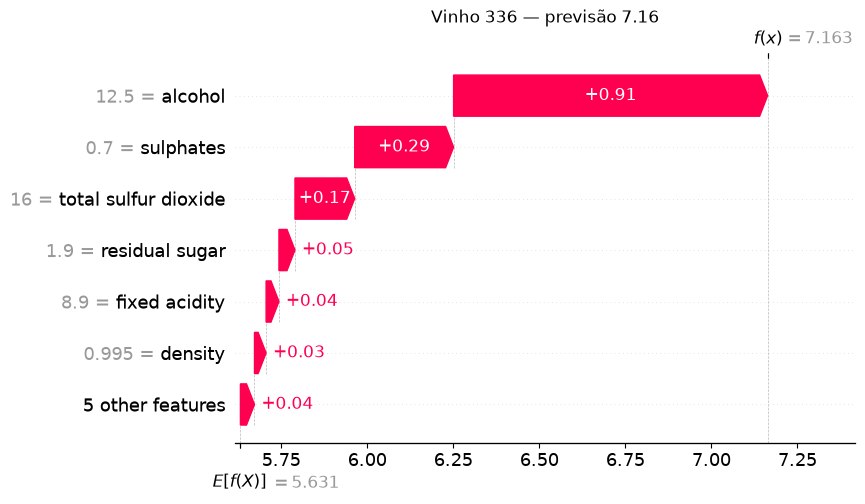

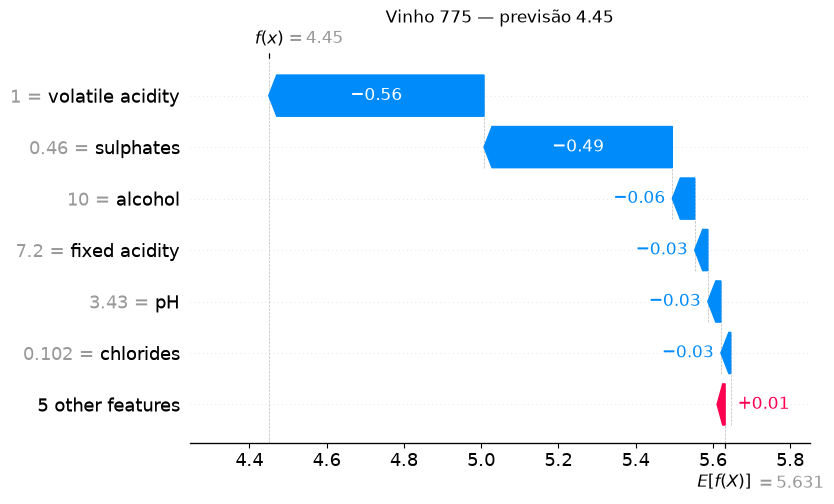

In [15]:
for i in [i_best, i_worst]:
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=7, show=False)
    plt.title(f'Vinho {x_test.index[i]} — previsão {pred[i]:.2f}')
    plt.savefig(f'p1_waterfall_{x_test.index[i]}.png', dpi=150, bbox_inches='tight')
    plt.show()

# 2 · Do local ao global

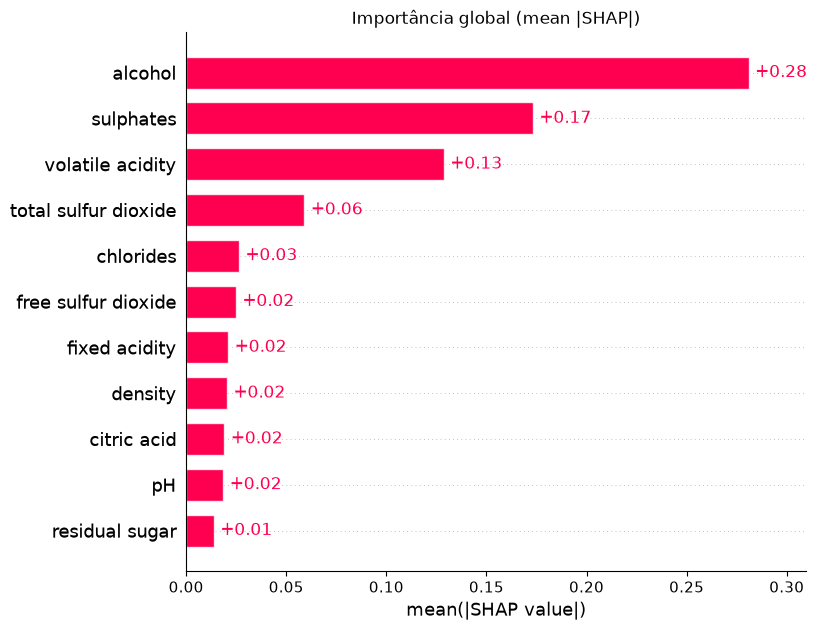

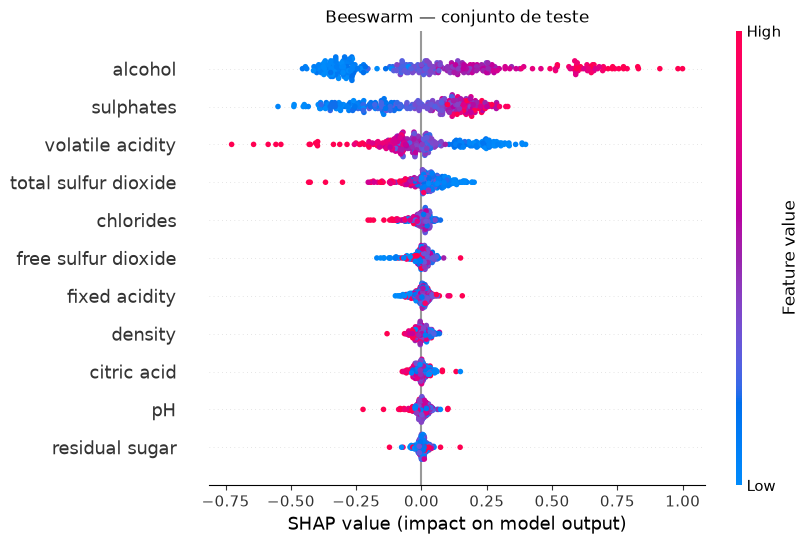

In [16]:
plt.figure()
shap.plots.bar(sv, max_display=12, show=False)
plt.title('Importância global (mean |SHAP|)')
plt.savefig('p2_bar_global.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure()
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title('Beeswarm — conjunto de teste')
plt.savefig('p2_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
abs_sv = np.abs(sv.values)
corr = [np.corrcoef(x_test[f], sv[:, f].values)[0, 1] for f in feature_names]

glob = pd.DataFrame({
    'Mean |SHAP|': abs_sv.mean(axis=0),
    'Max |SHAP|': abs_sv.max(axis=0),
    'Corr(valor, SHAP)': corr,
    'RF importance': model.feature_importances_,
}, index=feature_names)

glob['Rank SHAP'] = glob['Mean |SHAP|'].rank(ascending=False).astype(int)
glob['High values push quality'] = np.where(glob['Corr(valor, SHAP)'].abs() < 0.2, 'misto',
                                   np.where(glob['Corr(valor, SHAP)'] > 0, 'up', 'down'))
glob['Rank RF'] = glob['RF importance'].rank(ascending=False).astype(int)
glob['Max / Mean'] = glob['Max |SHAP|'] / glob['Mean |SHAP|']

table_glob = glob[['Mean |SHAP|', 'Rank SHAP', 'High values push quality', 'Rank RF',
                   'Max |SHAP|', 'Max / Mean', 'Corr(valor, SHAP)']].sort_values('Rank SHAP').round(3)
display(table_glob)

,Mean |SHAP|,Rank SHAP,High values push quality,Rank RF,Max |SHAP|,Max / Mean,"Corr(valor, SHAP)"
alcohol,0.281,1,up,1,0.999,3.557,0.959
sulphates,0.173,2,up,3,0.549,3.173,0.703
volatile acidity,0.129,3,down,2,0.727,5.651,-0.918
total sulfur dioxide,0.059,4,down,4,0.432,7.326,-0.756
chlorides,0.026,5,down,5,0.204,7.774,-0.575
free sulfur dioxide,0.025,6,misto,11,0.171,6.896,0.131
fixed acidity,0.021,7,up,6,0.156,7.465,0.290
density,0.020,8,down,9,0.132,6.488,-0.640
citric acid,0.019,9,down,10,0.149,7.836,-0.417
pH,0.018,10,down,8,0.224,12.115,-0.416


In [18]:
display(table_glob.sort_values('Max / Mean', ascending=False).head(5))

,Mean |SHAP|,Rank SHAP,High values push quality,Rank RF,Max |SHAP|,Max / Mean,"Corr(valor, SHAP)"
pH,0.018,10,down,8,0.224,12.115,-0.416
residual sugar,0.014,11,up,7,0.148,10.763,0.216
citric acid,0.019,9,down,10,0.149,7.836,-0.417
chlorides,0.026,5,down,5,0.204,7.774,-0.575
fixed acidity,0.021,7,up,6,0.156,7.465,0.290


Correlação de Spearman entre rankings: 0.773


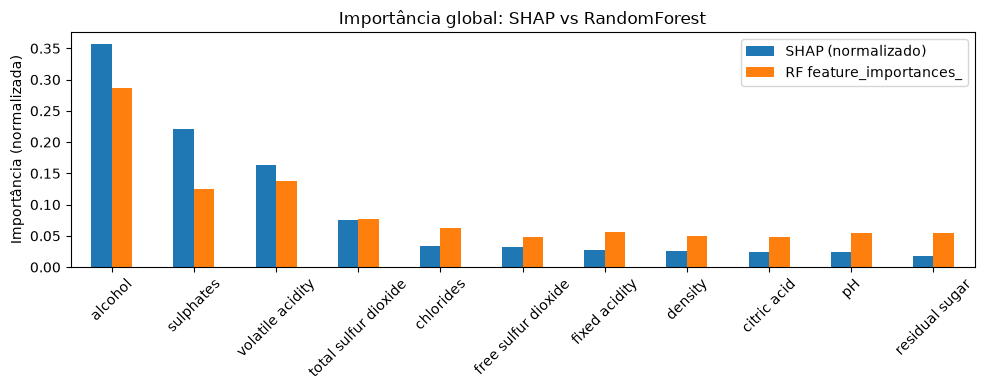

In [19]:
rho = glob['Rank SHAP'].corr(glob['Rank RF'], method='spearman')
print(f'Correlação de Spearman entre rankings: {rho:.3f}')

comp = pd.DataFrame({
    'SHAP (normalizado)': glob['Mean |SHAP|'] / glob['Mean |SHAP|'].sum(),
    'RF feature_importances_': glob['RF importance'],
}).sort_values('SHAP (normalizado)', ascending=False)

comp.plot.bar(figsize=(10, 4), rot=45, title='Importância global: SHAP vs RandomForest')
plt.ylabel('Importância (normalizada)')
plt.tight_layout()
plt.savefig('p2_shap_vs_rf.png', dpi=150)
plt.show()

# 3 · Explorar mais

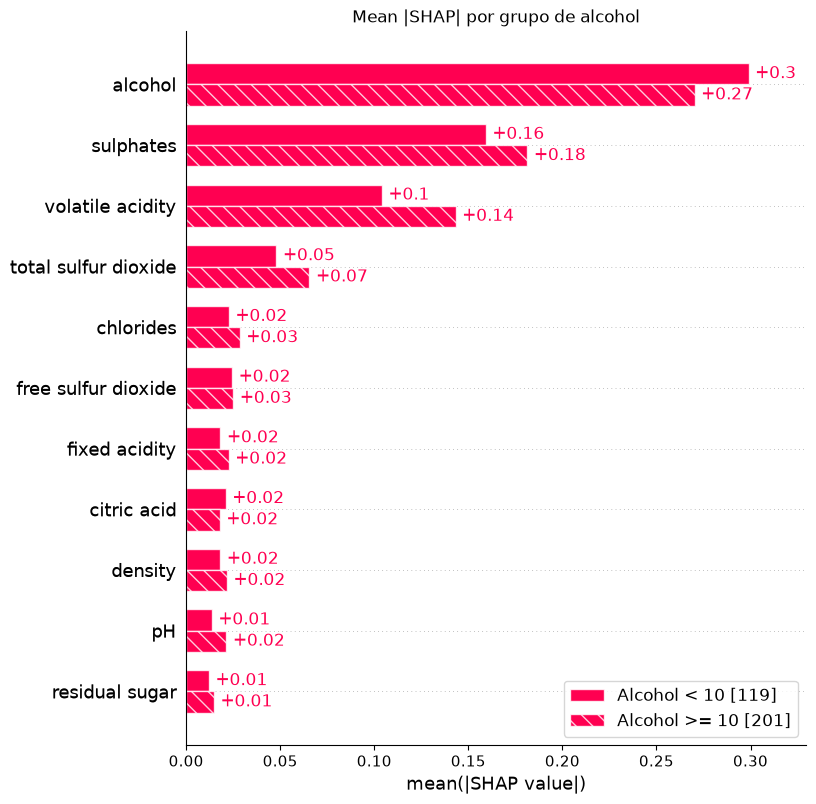

In [20]:
alcohol_group = list(np.where(x_test['alcohol'] >= 10, 'Alcohol >= 10', 'Alcohol < 10'))
plt.figure()
shap.plots.bar(sv.cohorts(alcohol_group).abs.mean(0), max_display=12, show=False)
plt.title('Mean |SHAP| por grupo de alcohol')
plt.savefig('p3_cohorts_alcohol.png', dpi=150, bbox_inches='tight')
plt.show()

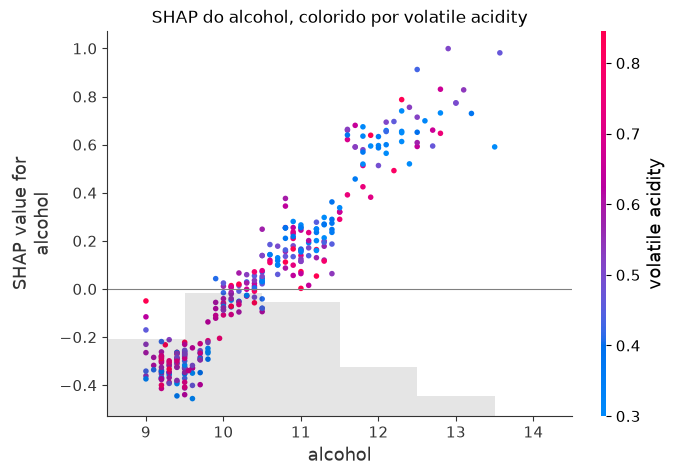

In [21]:
shap.plots.scatter(sv[:, 'alcohol'], color=sv[:, 'volatile acidity'], show=False)
plt.axhline(0, color='grey', lw=0.8)
plt.title('SHAP do alcohol, colorido por volatile acidity')
plt.savefig('p3_interacao.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
bg = shap.sample(x_train, 50, random_state=123)
explainer_int = shap.TreeExplainer(model, data=bg, feature_perturbation='interventional')

t0 = time.time()
sv_int = explainer_int(x_test)
print(f'Interventional: {time.time() - t0:.0f}s')

print('Base value tree_path_dependent:', round(float(sv.base_values[0]), 3))
print('Base value interventional:     ', round(float(sv_int.base_values[0]), 3))

ref = pd.DataFrame({
    'Mean |SHAP| (default)': np.abs(sv.values).mean(axis=0),
    'Mean |SHAP| (interventional)': np.abs(sv_int.values).mean(axis=0),
    'Correlação por vinho': [np.corrcoef(sv.values[:, j], sv_int.values[:, j])[0, 1]
                             for j in range(len(feature_names))],
}, index=feature_names).round(3).sort_values('Mean |SHAP| (default)', ascending=False)
display(ref)

Interventional: 6s
Base value tree_path_dependent: 5.631
Base value interventional:      5.64


,Mean |SHAP| (default),Mean |SHAP| (interventional),Correlação por vinho
alcohol,0.281,0.245,0.998
sulphates,0.173,0.170,0.990
volatile acidity,0.129,0.126,0.994
total sulfur dioxide,0.059,0.054,0.989
chlorides,0.026,0.025,0.991
free sulfur dioxide,0.025,0.023,0.988
fixed acidity,0.021,0.022,0.979
density,0.020,0.025,0.952
citric acid,0.019,0.022,0.953
pH,0.018,0.019,0.981


# 4 · Comparar com LIME (sem ICE)

In [23]:
order = np.argsort(pred)
chosen = [order[0], order[len(order) // 2], order[-1]]
i_alc = feature_names.index('alcohol')

def make_lime(seed=123):
    return lime.lime_tabular.LimeTabularExplainer(
        x_train.values,
        mode='regression',
        feature_names=feature_names,
        discretize_continuous=True,
        random_state=seed)

rows = []
for i in chosen:
    x = x_test.iloc[i].values
    weights, scores, cond = [], [], None
    for seed in range(10):
        e = make_lime(seed).explain_instance(x, model.predict, num_features=len(feature_names))
        weights.append(dict(e.as_map()[1])[i_alc])
        scores.append(e.score)
        cond = next(c for c, _ in e.as_list() if 'alcohol' in c)
    rows.append({
        'Wine': x_test.index[i],
        'Predicted quality': round(pred[i], 3),
        'Alcohol': x_test.iloc[i]['alcohol'],
        'SHAP of alcohol': round(sv.values[i, i_alc], 3),
        'LIME condição': cond,
        'LIME weight of alcohol (média)': round(np.mean(weights), 3),
        'LIME weight (std, 10 seeds)': round(np.std(weights), 3),
        'LIME R²': round(np.mean(scores), 3),
    })

table_cmp = pd.DataFrame(rows)
display(table_cmp)

,Wine,Predicted quality,Alcohol,SHAP of alcohol,LIME condição,LIME weight of alcohol (média),"LIME weight (std, 10 seeds)",LIME R²
0,775,4.450,10.0,-0.058,9.50 < alcohol <= 10.10,-0.241,0.005,0.267
1,632,5.633,10.5,0.071,10.10 < alcohol <= 11.00,0.071,0.016,0.014
2,336,7.163,12.5,0.912,alcohol > 11.00,0.632,0.007,0.425


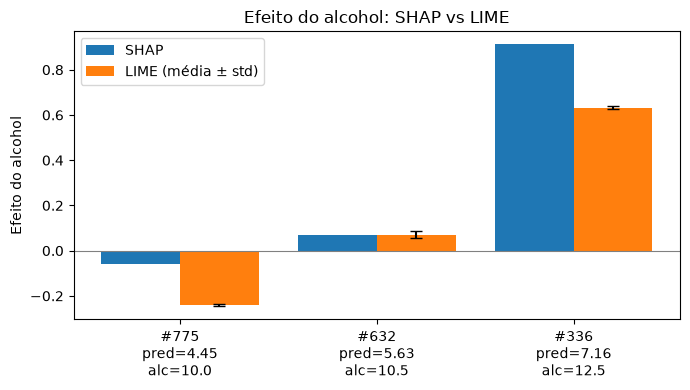

In [24]:
xpos = np.arange(len(table_cmp))
plt.figure(figsize=(7, 4))
plt.bar(xpos - 0.2, table_cmp['SHAP of alcohol'], width=0.4, label='SHAP')
plt.bar(xpos + 0.2, table_cmp['LIME weight of alcohol (média)'], width=0.4,
        yerr=table_cmp['LIME weight (std, 10 seeds)'], capsize=4, label='LIME (média ± std)')
plt.axhline(0, color='grey', lw=0.8)
plt.xticks(xpos, [f"#{w}\npred={p:.2f}\nalc={a}" for w, p, a in
                  zip(table_cmp['Wine'], table_cmp['Predicted quality'], table_cmp['Alcohol'])])
plt.ylabel('Efeito do alcohol')
plt.title('Efeito do alcohol: SHAP vs LIME')
plt.legend()
plt.tight_layout()
plt.savefig('p4_shap_vs_lime.png', dpi=150)
plt.show()